# WGAN-GP on MNIST: a speed limit for the critic that is actually enforced

**The question:** the Wasserstein GAN needs its critic to be "smooth": the critic's score may not change faster than the images do (a "1-Lipschitz" function). The original WGAN enforced this by clamping every critic weight into a tiny range, which is crude and, as the WGAN notebook showed, touchy. **WGAN-GP** replaces clipping with a **gradient penalty**: at random points between real and generated digits, it punishes the critic whenever the size of its gradient strays from 1. *Does the penalty really hold the gradient near 1 where clipping does not, does it give better digits for the same effort, how much does the penalty weight matter, and why does the paper insist on removing batch norm from the critic?* Quality is judged by an independent referee network, not by the loss.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. The referee: a way to judge generated digits
4. Hypotheses and why we chose each test
5. The models and the two ways to limit the critic
6. H1: does the penalty hold the gradient near 1?
7. H2: does it give better digits than clipping?
8. H3: how much does the penalty weight matter?
9. H4: why not batch norm?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab GAN/wgan-gp/wgan_gp.ipynb`, or *Run All* in any Jupyter. MNIST (about 12 MB) downloads itself on the first run. It uses a GPU if present and takes about an hour on one.

## 1. 💡 The simple analogy

Back to the **forger and the judge (critic)** who scores paintings.

- For the judge's scores to be useful, they must not **jump wildly** between two paintings that look almost the same: a "speed limit" on how fast the score may change as the painting changes.
- **Weight clipping** enforces the limit by **bolting the judge's brain into a tiny box**: every number inside it is clamped. The limit is met only by accident, and the judge is often so restricted that his scores barely change at all.
- The **gradient penalty** enforces it by **checking the speed directly**: take two paintings (a real one and a fake one), pick a spot in between, see how fast the score is changing there, and fine the judge if it is not about 1. The judge is free to be as sharp as he likes inside the limit.
- One more rule: the check is made **one painting at a time**, so the judge must not be allowed to peek at the other paintings in the batch (batch norm). Otherwise one painting's score depends on its neighbours and the check means nothing.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the image size and the training budget keeps the notebook reproducible and avoids "magic numbers". **We use 32 x 32 images** (MNIST digits padded out from 28 pixels) where the legacy scripts used 64 x 64: the smaller size is far cheaper to train on one small GPU. Each run is **2,500 generator updates** with 5 critic updates each and batches of 64.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy import stats
from torch import nn
from torchvision import datasets

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
IMAGE_SIZE = 32  # MNIST digits are padded out from 28 to 32 pixels (the legacy scripts used 64)
Z_DIM = 100
FEATURES = 32  # width multiplier of the generator and the critic
N_EVAL = 10_000  # generated images used for the final scores
N_BOOTSTRAP = 2_000
BATCH = 64
GEN_STEPS = 2_500  # generator updates per training run
TRACK_EVERY = 250
CRITIC_STEPS = 5  # critic updates per generator update
N_SEEDS = 3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. The referee: a way to judge generated digits

*What:* a GAN has no accuracy to report, so we build an **independent referee**: a small digit classifier trained only on real MNIST digits. It gives us three scores for any set of generated digits:

- **Fréchet distance (FD):** compare the *average and spread* of the referee's internal description of the generated digits with those of real test digits. Zero means identical; lower is better.
- **Inception-style score:** high only if the referee is **sure** about each image *and* all ten digits appear (a perfect score is 10).
- **Confident share:** the share of images the referee is more than 90% sure about.

We also report the **total variation distance (TVD)** between the digit mix of the generated images and the real digit mix (0 means identical mixes), which catches a generator that favours a few digits.

In [2]:
def load_mnist() -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads MNIST as uint8 tensors (N, 28, 28) with labels, on the compute device.

    Returns:
        Training images and labels, then test images and labels.

    Raises:
        ValueError: If the dataset does not have the expected shape.
    """
    with contextlib.redirect_stderr(io.StringIO()):  # hide the download progress bars
        train = datasets.MNIST(DATA_DIR, train=True, download=True)
        test = datasets.MNIST(DATA_DIR, train=False, download=True)
    if tuple(train.data.shape) != (60_000, 28, 28) or tuple(test.data.shape) != (10_000, 28, 28):
        raise ValueError("Unexpected MNIST shape")
    return (
        train.data.to(DEVICE),
        train.targets.to(DEVICE),
        test.data.to(DEVICE),
        test.targets.to(DEVICE),
    )


def to_gan_scale(images: torch.Tensor) -> torch.Tensor:
    """Turns uint8 digits (N, 28, 28) into float images (N, 1, 32, 32) with values in [-1, 1]."""
    x = images.float().div(127.5).sub(1).unsqueeze(1)
    return F.interpolate(x, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)


def to_referee_scale(images: torch.Tensor) -> torch.Tensor:
    """Turns GAN-scale images (N, 1, 32, 32) back to (N, 1, 28, 28) in [0, 1] for the referee."""
    small = F.interpolate((images + 1) / 2, size=(28, 28), mode="area")
    return small.clamp(0, 1)


class Referee(nn.Module):
    """A small digit classifier (trained on real digits) used to judge generated images."""

    def __init__(self) -> None:
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
        )
        self.head = nn.Linear(128, 10)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """Returns class scores and the 128-number feature vector."""
        features = self.conv(x)
        return self.head(features), features


train_x, train_y, test_x, test_y = load_mnist()
torch.manual_seed(SEED)
referee = Referee().to(DEVICE)
optimizer = torch.optim.Adam(referee.parameters(), lr=1e-3)
for _ in range(3):
    order = torch.randperm(len(train_x), device=DEVICE)
    for start in range(0, len(order), 128):
        pick = order[start : start + 128]
        scores, _ = referee(train_x[pick].float().div(255).unsqueeze(1))
        loss = F.cross_entropy(scores, train_y[pick])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
referee.eval()


def referee_outputs(images01: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:
    """Class probabilities and features for images in [0, 1] of shape (N, 1, 28, 28).

    Args:
        images01: Images scaled to [0, 1].

    Returns:
        Probabilities (N, 10) and features (N, 128) as NumPy arrays.
    """
    probs, feats = [], []
    with torch.no_grad():
        for start in range(0, len(images01), 2000):
            scores, f = referee(images01[start : start + 2000])
            probs.append(F.softmax(scores, dim=1).cpu().numpy())
            feats.append(f.cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats).astype(np.float64)


test_probs, test_feats = referee_outputs(test_x.float().div(255).unsqueeze(1))
train_probs, train_feats = referee_outputs(train_x.float().div(255).unsqueeze(1))
REAL_MU, REAL_COV = test_feats.mean(0), np.cov(test_feats, rowvar=False)
real_share = np.bincount(test_y.cpu().numpy(), minlength=10) / len(test_y)
print(
    f"Referee accuracy on the real test digits: "
    f"{(test_probs.argmax(1) == test_y.cpu().numpy()).mean():.2%}"
)
print(
    f"Real digits per class in the test set: min {real_share.min():.1%}, max {real_share.max():.1%}"
)


def frechet_distance(
    feats: np.ndarray, mu_ref: np.ndarray = REAL_MU, cov_ref: np.ndarray = REAL_COV
) -> float:
    """Frechet distance between two clouds of referee features (lower = more alike).

    It compares the mean and spread of the features of some images with those of the real test
    digits; it is the digit-sized cousin of the FID used for photographs.

    Args:
        feats: Features of the images to judge, shape (N, 128).
        mu_ref: Mean of the reference features.
        cov_ref: Covariance of the reference features.

    Returns:
        The Frechet distance.
    """
    mu, cov = feats.mean(0), np.cov(feats, rowvar=False)
    # trace of the matrix square root of cov @ cov_ref = sum of square roots of its eigenvalues,
    # which are real and non-negative because both matrices are covariance matrices
    eigenvalues = np.linalg.eigvals(cov @ cov_ref).real.clip(min=0)
    return float(
        np.sum((mu - mu_ref) ** 2) + np.trace(cov + cov_ref) - 2 * np.sqrt(eigenvalues).sum()
    )


def inception_style_score(probs: np.ndarray) -> float:
    """exp(average KL divergence between each image's class guess and the overall class mix).

    High when every image is clearly one digit AND all ten digits appear. A perfect score is 10.

    Args:
        probs: Referee class probabilities, shape (N, 10).

    Returns:
        The score.
    """
    marginal = probs.mean(0, keepdims=True)
    kl = (probs * (np.log(probs + 1e-12) - np.log(marginal + 1e-12))).sum(1)
    return float(np.exp(kl.mean()))


@torch.no_grad()
def judge(generator: nn.Module, n: int = N_EVAL, seed: int = 0) -> dict:
    """Scores a generator: Frechet distance, Inception-style score, confidence and class mix.

    Args:
        generator: The generator to judge (it is run in training mode, so batch normalisation
            uses the statistics of each batch of 1,000 images, as when it was trained).
        n: Number of images to generate.
        seed: Seed for the random noise, so every generator sees the same noise.

    Returns:
        A dict with ``fd``, ``is``, ``confident`` (share of images the referee is more than 90%
        sure about), ``tvd`` (total variation distance of the class mix from the real one) and
        ``share`` (the class mix).
    """
    generator.train()
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
    images = torch.cat(
        [
            generator(torch.randn(1000, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
            for _ in range(n // 1000)
        ]
    )
    probs, feats = referee_outputs(to_referee_scale(images))
    share = np.bincount(probs.argmax(1), minlength=10) / len(probs)
    return {
        "fd": frechet_distance(feats),
        "is": inception_style_score(probs),
        "confident": float((probs.max(1) > 0.9).mean()),
        "tvd": float(0.5 * np.abs(share - real_share).sum()),
        "share": share,
    }


floor_rows = []
for i in range(5):
    sub = np.random.default_rng(i).choice(len(train_feats), N_EVAL, replace=False)
    floor_rows.append(
        {
            "fd": frechet_distance(train_feats[sub]),
            "is": inception_style_score(train_probs[sub]),
            "confident": float((train_probs[sub].max(1) > 0.9).mean()),
        }
    )
floor = pd.DataFrame(floor_rows)
print(
    f"Real digits judged the same way (10,000 real training digits against the real test "
    f"digits, 5 draws):\n  Frechet distance {floor['fd'].mean():.2f} "
    f"(range {floor['fd'].min():.2f} to {floor['fd'].max():.2f}), Inception-style score "
    f"{floor['is'].mean():.2f}, referee confident on {floor['confident'].mean():.1%}"
)

Referee accuracy on the real test digits: 98.92%
Real digits per class in the test set: min 8.9%, max 11.3%


Real digits judged the same way (10,000 real training digits against the real test digits, 5 draws):
  Frechet distance 1.89 (range 1.78 to 2.01), Inception-style score 9.59, referee confident on 96.6%


**How to read this:**

- **The referee is accurate:** it reads **98.92%** of the real test digits correctly.
- **The real-digit floor:** real training digits scored against the test digits give a Fréchet distance of **1.89** (range 1.78 to 2.01 over five draws), an Inception-style score of **9.59** (out of 10) and a referee that is confident on **96.6%** of images. A generator is judged against these numbers.
- **Real test digits are not perfectly balanced:** the commonest digit makes up **11.3%** and the rarest **8.9%**.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the gradient penalty hold the critic's gradient closer to 1 than weight clipping does? | Same distance from 1 | Penalty is closer | Average distance of the gradient size from 1, at points between real and fake digits; one-sided Mann-Whitney, 3 seeds each |
| H2 | Does the penalty give better digits than clipping after the same number of updates? | Same Fréchet distance | Penalty is lower | One-sided Mann-Whitney, 3 seeds each |
| H3 | Does the penalty weight λ matter (0, 1, 10, 100)? | Same quality | Differs | Kruskal-Wallis on the Fréchet distance; the gradient size per setting |
| H4 | Does the choice of normalisation in the critic matter (instance, batch, none)? | Same quality | Differs | Kruskal-Wallis on the Fréchet distance |

*Why these tests?* With only two or three seeds per setting, only rank-based tests are safe, and the smallest p-value that 3 runs against 3 can give is **0.05** (one-sided), so we read the *size* of each effect and whether it holds in every run, together with the p-value. The side experiments (H3 and H4) use **2 seeds per setting** to keep the notebook affordable; we say so wherever it matters.

## 5. The models and the two ways to limit the critic

*What:* the same generator as before (noise of 100 numbers → three transposed-convolution blocks → a 32 x 32 image), a critic that outputs an unbounded score (instance norm between layers by default), and a single training function with two ways to limit it:

- **Gradient penalty (WGAN-GP):** the critic loss is *average fake score minus average real score* **plus λ x (gradient size - 1)²**, averaged over random points on the line between a real and a generated digit. **Adam** (learning rate 0.0001, momentum 0.0 and 0.9), λ = 10, 5 critic updates per generator update.
- **Weight clipping (the original WGAN):** after every critic update all critic weights are clamped to [-0.01, 0.01]; **RMSprop** with learning rate 0.00005.
- Every 250 generator updates we record the Fréchet distance of 5,000 forged digits, and at the end we measure the **size of the critic's gradient** at 1,000 points between real and generated digits.

> **Problems in the legacy scripts this replaces:** training only wrote sample grids to TensorBoard with **no measurement of quality** and no check that the gradient penalty did what the paper says; the paper itself was included as a PDF.

In [3]:
class Generator(nn.Module):
    """DCGAN generator: noise (N, 100, 1, 1) -> image (N, 1, 32, 32) with values in [-1, 1].

    Args:
        features: Width multiplier (the legacy scripts use 64).
    """

    def __init__(self, features: int = FEATURES) -> None:
        super().__init__()

        def block(c_in: int, c_out: int, k: int, s: int, p: int) -> nn.Sequential:
            return nn.Sequential(
                nn.ConvTranspose2d(c_in, c_out, k, s, p, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
            )

        self.net = nn.Sequential(
            block(Z_DIM, features * 8, 4, 1, 0),  # 4 x 4
            block(features * 8, features * 4, 4, 2, 1),  # 8 x 8
            block(features * 4, features * 2, 4, 2, 1),  # 16 x 16
            nn.ConvTranspose2d(features * 2, 1, 4, 2, 1),  # 32 x 32
            nn.Tanh(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        """Turns noise into images."""
        return self.net(z)


def init_weights(model: nn.Module) -> None:
    """Draws every convolution and normalisation weight from N(0, 0.02), as the DCGAN paper does."""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.BatchNorm2d)):
            nn.init.normal_(m.weight.data, 0.0, 0.02)

In [4]:
class Critic(nn.Module):
    """The discriminator / critic: image (N, 1, 32, 32) -> one score per image.

    Args:
        features: Width multiplier.
        norm: ``"batch"``, ``"instance"`` or ``"none"`` normalisation between layers.
        sigmoid: Squash the score to (0, 1), as a standard GAN discriminator does.
    """

    def __init__(
        self, features: int = FEATURES, norm: str = "batch", sigmoid: bool = False
    ) -> None:
        super().__init__()

        def make_norm(c: int) -> nn.Module:
            if norm == "batch":
                return nn.BatchNorm2d(c)
            if norm == "instance":
                return nn.InstanceNorm2d(c, affine=True)
            return nn.Identity()

        def block(c_in: int, c_out: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False), make_norm(c_out), nn.LeakyReLU(0.2)
            )

        layers: list[nn.Module] = [
            nn.Conv2d(1, features, 4, 2, 1),
            nn.LeakyReLU(0.2),  # 16 x 16
            block(features, features * 2),  # 8 x 8
            block(features * 2, features * 4),  # 4 x 4
            nn.Conv2d(features * 4, 1, 4, 1, 0),
        ]  # 1 x 1
        if sigmoid:
            layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """One score per image."""
        return self.net(x).reshape(-1)

In [5]:
def real_batches(batch: int, seed: int):
    """Endless stream of random batches of real digits at GAN scale.

    Args:
        batch: Batch size.
        seed: Seed for the shuffling.

    Yields:
        Tensors of shape (batch, 1, 32, 32).
    """
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
    while True:
        order = torch.randperm(len(train_x), device=DEVICE, generator=gen_cuda)
        for start in range(0, len(order) - batch + 1, batch):
            yield to_gan_scale(train_x[order[start : start + batch]])


def show_grid(generator: nn.Module, ax: plt.Axes, seed: int = 123, n: int = 64) -> None:
    """Draws an 8 x 8 grid of generated digits on an axis.

    Args:
        generator: The generator.
        ax: The axis to draw on.
        seed: Seed for the noise.
        n: Number of images (a square number).
    """
    side = int(np.sqrt(n))
    with torch.no_grad():
        gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
        images = generator(torch.randn(n, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
    grid = images.cpu().numpy()[:, 0].reshape(side, side, IMAGE_SIZE, IMAGE_SIZE)
    ax.imshow(
        grid.transpose(0, 2, 1, 3).reshape(side * IMAGE_SIZE, side * IMAGE_SIZE),
        cmap="gray",
        vmin=-1,
        vmax=1,
    )
    ax.axis("off")

In [6]:
def gradient_norms(critic: nn.Module, real: torch.Tensor, fake: torch.Tensor) -> torch.Tensor:
    """Size of the critic's gradient at random points between real and generated images.

    The WGAN theory needs this to be at most 1 everywhere (a "1-Lipschitz" critic).

    Args:
        critic: The critic.
        real: A batch of real images.
        fake: A batch of generated images (same size).

    Returns:
        One gradient norm per image pair.
    """
    mix = torch.rand(len(real), 1, 1, 1, device=real.device)
    points = (real * mix + fake * (1 - mix)).requires_grad_(True)
    scores = critic(points)
    grads = torch.autograd.grad(scores.sum(), points, create_graph=True)[0]
    return grads.flatten(1).norm(2, dim=1)


def train_wgan(
    seed: int,
    mode: str = "gp",
    lam: float = 10.0,
    norm: str = "instance",
    clip: float = 0.01,
    steps: int = GEN_STEPS,
) -> dict:
    """Trains a Wasserstein GAN whose critic is kept in check by a gradient penalty or by clipping.

    Args:
        seed: Seed for the weights, batches and noise.
        mode: ``"gp"`` (gradient penalty with weight ``lam``) or ``"clip"`` (weight clipping).
        lam: Gradient-penalty weight (0 means the critic is not constrained at all).
        norm: Normalisation inside the critic: ``"instance"``, ``"batch"`` or ``"none"``.
        clip: Clipping bound, used when ``mode`` is ``"clip"``.
        steps: Number of generator updates.

    Returns:
        A dict with the trained ``gen`` and ``critic``, the checkpoint ``history`` table, and
        the ``grad_norms`` of the final critic at 1,000 points between real and generated digits.
    """
    torch.manual_seed(seed)
    gen, critic = Generator().to(DEVICE), Critic(FEATURES, norm).to(DEVICE)
    init_weights(gen)
    init_weights(critic)
    if mode == "gp":
        opt_gen = torch.optim.Adam(gen.parameters(), lr=1e-4, betas=(0.0, 0.9))
        opt_critic = torch.optim.Adam(critic.parameters(), lr=1e-4, betas=(0.0, 0.9))
    else:
        opt_gen = torch.optim.RMSprop(gen.parameters(), lr=5e-5)
        opt_critic = torch.optim.RMSprop(critic.parameters(), lr=5e-5)
    stream = real_batches(BATCH, seed)
    rows = []
    for step in range(1, steps + 1):
        for _ in range(CRITIC_STEPS):
            real = next(stream)
            with torch.no_grad():
                fake = gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))
            loss_critic = -(critic(real).mean() - critic(fake).mean())
            if mode == "gp" and lam > 0:
                penalty = ((gradient_norms(critic, real, fake) - 1) ** 2).mean()
                loss_critic = loss_critic + lam * penalty
            opt_critic.zero_grad()
            loss_critic.backward()
            opt_critic.step()
            if mode == "clip":
                for p in critic.parameters():
                    p.data.clamp_(-clip, clip)
        loss_gen = -critic(gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))).mean()
        opt_gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()
        if step % TRACK_EVERY == 0:
            rows.append({"step": step, "fd": judge(gen, 5_000, seed=1)["fd"]})
    norms = []
    for _ in range(4):
        real = next(stream)
        with torch.no_grad():
            fake = gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))
        norms.append(gradient_norms(critic, real, fake).detach())
    return {
        "gen": gen,
        "critic": critic,
        "history": pd.DataFrame(rows),
        "grad_norms": torch.cat(norms).cpu().numpy(),
    }

**How to read this:** the next sections train seven settings (3 seeds for the two core settings, 2 for each side experiment) and measure them with the referee. The core comparison, penalty against clipping, is used in H1 and H2.

## 6. H1: does the penalty hold the gradient near 1?

*What:* after training, take 1,000 points between real and generated digits and measure the **size of the critic's gradient** at each. The theory needs it to be at most 1; the gradient penalty asks for exactly 1. For each run we compute the average distance of the gradient size from 1, and compare penalty and clipping with a one-sided Mann-Whitney test. *Why:* it checks the *mechanism*, not just the picture quality: if the penalty did not hold the gradient near 1, the theory would not apply.

In [7]:
SETTINGS = {
    "gradient penalty, lambda 10": {"mode": "gp", "lam": 10.0},
    "weight clipping, 0.01": {"mode": "clip"},
    "no constraint (lambda 0)": {"mode": "gp", "lam": 0.0},
    "gradient penalty, lambda 1": {"mode": "gp", "lam": 1.0},
    "gradient penalty, lambda 100": {"mode": "gp", "lam": 100.0},
    "gradient penalty with batch norm": {"mode": "gp", "lam": 10.0, "norm": "batch"},
    "gradient penalty, no norm": {"mode": "gp", "lam": 10.0, "norm": "none"},
}
CORE = ["gradient penalty, lambda 10", "weight clipping, 0.01"]
N_SEEDS_ABLATION = 2  # the side experiments use fewer runs to keep the notebook affordable
results = {
    name: [
        train_wgan(seed, **kwargs) for seed in range(N_SEEDS if name in CORE else N_SEEDS_ABLATION)
    ]
    for name, kwargs in SETTINGS.items()
}
rows = []
for name, runs in results.items():
    for seed, run in enumerate(runs):
        score = judge(run["gen"])
        norms = run["grad_norms"]
        rows.append(
            {
                "setting": name,
                "seed": seed,
                "fd": score["fd"],
                "is": score["is"],
                "confident": score["confident"],
                "tvd": score["tvd"],
                "grad_mean": norms.mean(),
                "grad_sd": norms.std(),
                "grad_off": np.abs(norms - 1).mean(),
            }
        )
table = pd.DataFrame(rows)
core = CORE
print(
    "Size of the critic's gradient at points between real and generated digits (it should be "
    "about 1):"
)
print(
    table[table["setting"].isin(core)]
    .groupby("setting", sort=False)[["grad_mean", "grad_sd", "grad_off"]]
    .agg(["mean", "min", "max"])
    .round(3)
    .to_string()
)
gp_off = table[table["setting"] == core[0]]["grad_off"].to_numpy()
clip_off = table[table["setting"] == core[1]]["grad_off"].to_numpy()
mw = stats.mannwhitneyu(clip_off, gp_off, alternative="greater")
print(
    f"\nAverage distance of the gradient norm from 1: clipping {clip_off.mean():.3f} vs gradient "
    f"penalty {gp_off.mean():.3f}; clipping farther in all {len(clip_off)} runs: "
    f"{bool(clip_off.min() > gp_off.max())}; one-sided Mann-Whitney p = {mw.pvalue:.3f}"
)

Size of the critic's gradient at points between real and generated digits (it should be about 1):
                            grad_mean               grad_sd               grad_off              
                                 mean    min    max    mean    min    max     mean    min    max
setting                                                                                         
gradient penalty, lambda 10     1.140  1.101  1.163   0.169  0.148  0.183    0.160  0.129  0.180
weight clipping, 0.01           0.059  0.051  0.070   0.014  0.010  0.021    0.941  0.930  0.949

Average distance of the gradient norm from 1: clipping 0.941 vs gradient penalty 0.160; clipping farther in all 3 runs: True; one-sided Mann-Whitney p = 0.050


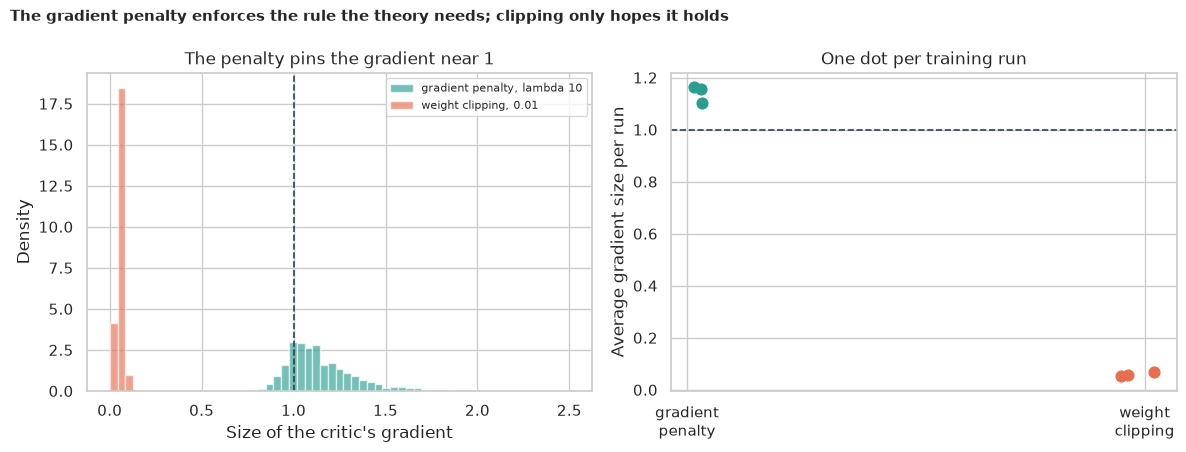

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, color in zip(core, [TEAL, ORANGE], strict=True):
    pooled = np.concatenate([r["grad_norms"] for r in results[name]])
    axes[0].hist(
        pooled,
        bins=np.linspace(0, max(2.5, np.percentile(pooled, 99)), 60),
        color=color,
        alpha=0.65,
        density=True,
        label=name,
    )
axes[0].axvline(1.0, color=NAVY, ls="--", lw=1.2)
axes[0].set_xlabel("Size of the critic's gradient")
axes[0].set_ylabel("Density")
axes[0].set_title("The penalty pins the gradient near 1")
axes[0].legend(fontsize=8)
for i, name in enumerate(core):
    sub = table[table["setting"] == name]["grad_mean"]
    axes[1].scatter(
        np.full(len(sub), i) + rng.uniform(-0.06, 0.06, len(sub)),
        sub,
        color=[TEAL, ORANGE][i],
        s=60,
    )
axes[1].axhline(1.0, color=NAVY, ls="--", lw=1.2)
axes[1].set_xticks(range(2), ["gradient\npenalty", "weight\nclipping"])
axes[1].set_ylabel("Average gradient size per run")
axes[1].set_title("One dot per training run")
fig.suptitle(
    "The gradient penalty enforces the rule the theory needs; clipping only hopes it holds",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_gradient_norms.png", dpi=150)
plt.show()

**How to read this:**

- **The penalty works as designed:** the average gradient size is **1.14** (1.10 to 1.16 across seeds), and the average distance from 1 is **0.16**.
- **Clipping does not hold it near 1; it makes the critic almost flat:** the average gradient size is **0.059** (0.051 to 0.070), and the average distance from 1 is **0.94**. The critic is far *under* the speed limit, which means it can barely tell digits apart (the WGAN notebook found 65% of its weights stuck at the clipping bound).
- **Clipping is farther from 1 in all 3 runs** (one-sided Mann-Whitney p = 0.050, the smallest value 3 against 3 runs can give). **We reject H₀** in the sense that the effect is as large and consistent as it can be with 3 runs.
- The histogram shows the whole picture: the penalty puts the gradients in a peak around 1, while clipping squeezes them into a spike near 0.

## 7. H2: does it give better digits than clipping?

*What:* after the same **2,500 generator updates** (5 critic updates each), score 10,000 forged digits from each of the 3 runs per setting with the referee. We compare the Fréchet distance with a one-sided Mann-Whitney test and look at the sample grids and learning curves. *Why:* a better-behaved critic is only interesting if the pictures improve.

In [9]:
a = table[table["setting"] == core[0]]["fd"].to_numpy()
b = table[table["setting"] == core[1]]["fd"].to_numpy()
print(f"After {GEN_STEPS:,} generator updates ({CRITIC_STEPS} critic updates each):")
print(
    table[table["setting"].isin(core)]
    .groupby("setting", sort=False)[["fd", "is", "confident", "tvd"]]
    .agg(["mean", "min", "max"])
    .round(2)
    .to_string()
)
mw = stats.mannwhitneyu(a, b, alternative="less")
print(
    f"\nGradient penalty minus clipping, Frechet distance: {a.mean() - b.mean():+.1f}; penalty "
    f"better than every clipping run: {bool(a.max() < b.min())}; one-sided Mann-Whitney "
    f"p = {mw.pvalue:.3f} (the smallest possible with 3 against 3 runs is 0.05)"
)

After 2,500 generator updates (5 critic updates each):
                                 fd                    is             confident               tvd            
                               mean     min     max  mean   min   max      mean   min   max  mean   min   max
setting                                                                                                      
gradient penalty, lambda 10  186.07  180.76  189.81  6.27  6.24  6.32      0.54  0.53  0.54  0.04  0.04  0.05
weight clipping, 0.01        456.42  404.95  505.83  3.73  3.56  3.96      0.31  0.29  0.33  0.31  0.24  0.38

Gradient penalty minus clipping, Frechet distance: -270.4; penalty better than every clipping run: True; one-sided Mann-Whitney p = 0.050 (the smallest possible with 3 against 3 runs is 0.05)


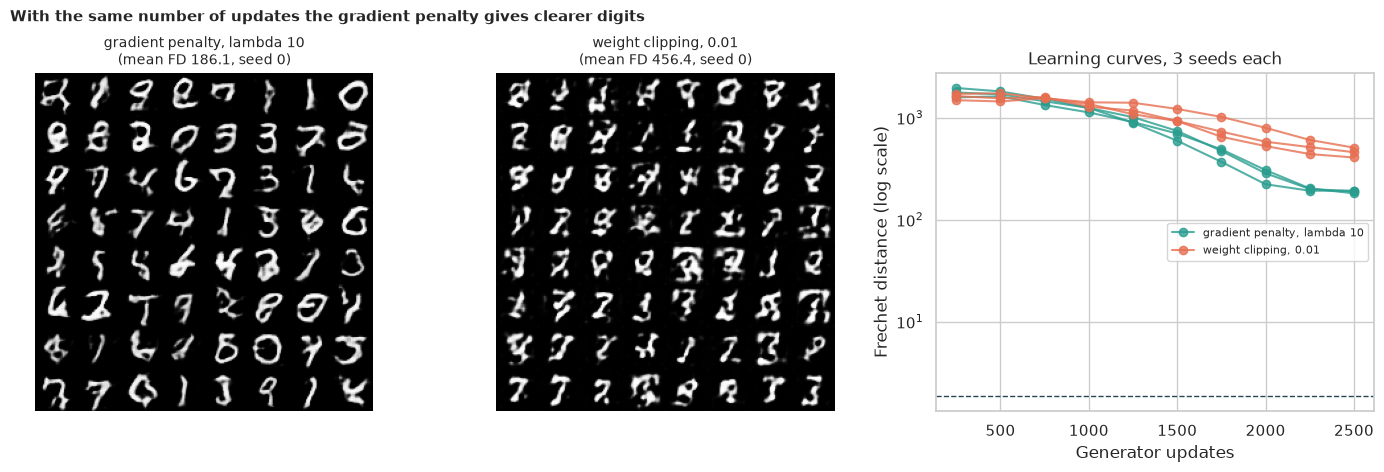

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, name in zip(axes[:2], core, strict=True):
    show_grid(results[name][0]["gen"], ax, n=64)
    mean_fd = table[table["setting"] == name]["fd"].mean()
    ax.set_title(f"{name}\n(mean FD {mean_fd:.1f}, seed 0)", fontsize=10)
for name, color in zip(core, [TEAL, ORANGE], strict=True):
    for i, run in enumerate(results[name]):
        axes[2].plot(
            run["history"]["step"],
            run["history"]["fd"],
            color=color,
            marker="o",
            alpha=0.8,
            label=name if i == 0 else None,
        )
axes[2].axhline(floor["fd"].mean(), color=NAVY, ls="--", lw=1)
axes[2].set_yscale("log")
axes[2].set_xlabel("Generator updates")
axes[2].set_ylabel("Frechet distance (log scale)")
axes[2].set_title("Learning curves, 3 seeds each")
axes[2].legend(fontsize=8)
fig.suptitle(
    "With the same number of updates the gradient penalty gives clearer digits",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_samples_and_curves.png", dpi=150)
plt.show()

**How to read this:**

- **The penalty gives much clearer digits:** mean Fréchet distance **186.1** (180.8 to 189.8) against **456.4** (405.0 to 505.8) for clipping, a difference of **270 points**. The Inception-style score is **6.27 against 3.73** and the referee is confident on **54% against 31%** of the images.
- **The penalty is better than every clipping run** (one-sided Mann-Whitney p = 0.050, the smallest possible with 3 against 3). **We reject H₀.** The digit mix is also far better: the total variation distance is **0.04** against **0.31** (clipping over- and under-produces some digits).
- **A sense of scale:** the real-digit floor is 1.89, so both recipes are far from real digits after only 2,500 updates. For context only (a different budget, in the WGAN notebook), the classic GAN reached 188 after 5,000 updates and the clipped WGAN 285.
- **The curves separate after about 1,000 updates:** all six runs start together near 1,500, then the three penalty runs fall steadily to about 190 while the clipping runs flatten out between 400 and 500. The sample grids show it: penalty digits are mostly recognisable, clipped ones are messy strokes.

## 8. H3: how much does the penalty weight matter?

*What:* the penalty weight λ says how hard the critic is fined for straying from a gradient of 1. We try **λ = 0** (no limit at all), **1**, **10** (the paper's value) and **100**, with 2 seeds each (3 for λ = 10), and compare the Fréchet distance (Kruskal-Wallis) and the gradient size. *Why:* it separates "the penalty helps" from "any penalty helps" and shows how sensitive the recipe is.

In [11]:
lam_names = [
    "no constraint (lambda 0)",
    "gradient penalty, lambda 1",
    "gradient penalty, lambda 10",
    "gradient penalty, lambda 100",
]
lam_table = table[table["setting"].isin(lam_names)]
print(
    lam_table.groupby("setting", sort=False)[["fd", "confident", "tvd", "grad_mean"]]
    .agg(["mean", "min", "max"])
    .round(2)
    .to_string()
)
kw = stats.kruskal(*[lam_table[lam_table["setting"] == n]["fd"].to_numpy() for n in lam_names])
print(
    f"\nKruskal-Wallis on the Frechet distance across the four penalty weights: "
    f"H = {kw.statistic:.1f}, p = {kw.pvalue:.3f}"
)

                                  fd                 confident               tvd                grad_mean                          
                                mean     min     max      mean   min   max  mean   min   max         mean          min          max
setting                                                                                                                            
gradient penalty, lambda 10   186.07  180.76  189.81      0.54  0.53  0.54  0.04  0.04  0.05     1.140000     1.100000     1.160000
no constraint (lambda 0)      382.01  360.41  403.61      0.35  0.34  0.36  0.26  0.24  0.29  3139.379883  2289.149902  3989.610107
gradient penalty, lambda 1    191.45  184.26  198.65      0.55  0.54  0.56  0.04  0.04  0.04     2.510000     2.340000     2.680000
gradient penalty, lambda 100  168.12  157.45  178.80      0.55  0.53  0.58  0.05  0.04  0.05     1.020000     1.000000     1.030000

Kruskal-Wallis on the Frechet distance across the four penalty weights: H =

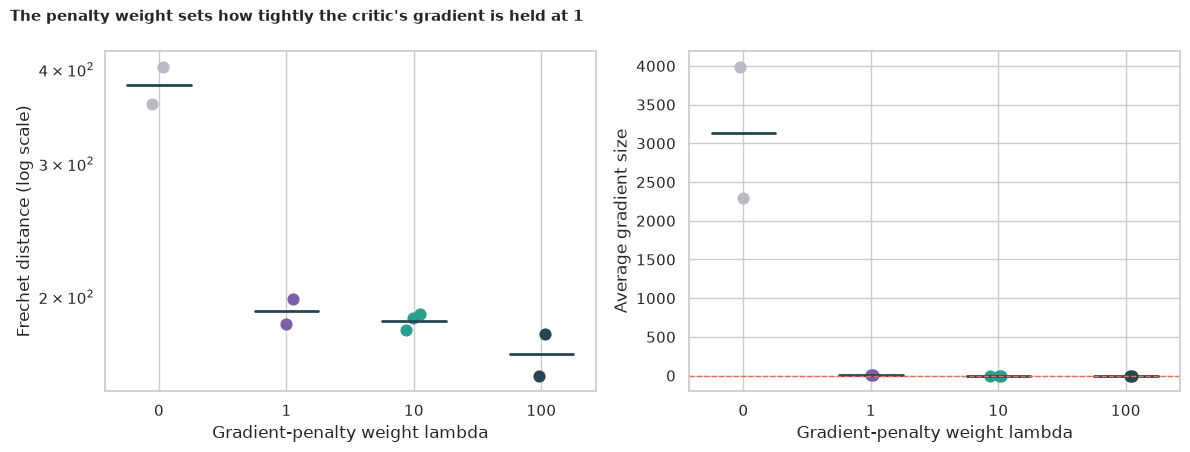

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, column, label in [
    (axes[0], "fd", "Frechet distance (log scale)"),
    (axes[1], "grad_mean", "Average gradient size"),
]:
    for i, name in enumerate(lam_names):
        sub = lam_table[lam_table["setting"] == name][column]
        ax.scatter(
            np.full(len(sub), i) + rng.uniform(-0.07, 0.07, len(sub)),
            sub,
            s=60,
            color=[GREY, PURPLE, TEAL, NAVY][i],
        )
        ax.plot([i - 0.25, i + 0.25], [sub.mean()] * 2, color=NAVY, lw=2)
    ax.set_xticks(range(4), ["0", "1", "10", "100"])
    ax.set_xlabel("Gradient-penalty weight lambda")
    ax.set_ylabel(label)
axes[0].set_yscale("log")
axes[1].axhline(1.0, color=ORANGE, ls="--", lw=1)
fig.suptitle(
    "The penalty weight sets how tightly the critic's gradient is held at 1",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_penalty_weight.png", dpi=150)
plt.show()

**How to read this:**

- **With no limit the critic's gradient explodes:** at λ = 0 the average gradient size is about **3,100** (2,289 to 3,990) and the Fréchet distance is **382.0** (360.4 to 403.6), with a confident share of only **35%**. Without the speed limit the critic's scores say little about how close the fakes are.
- **Any penalty helps, a larger one a little more:** the Fréchet distance is **191.5** at λ = 1 (gradient size 2.5), **186.1** at λ = 10 (1.14) and **168.1** at λ = 100 (1.02), with the confident share at 55%, 54% and 55%. A larger λ holds the gradient closer to 1.
- **The recipe is forgiving compared with clipping:** between λ = 1 and λ = 100 the Fréchet distance moves by about 23 points, against the 270-point gap to clipping in H2 and the 2-fold change across clipping bounds in the WGAN notebook.
- **The statistics are weak:** the Kruskal-Wallis test over the four weights gives p = **0.084**, with 2 or 3 runs per setting. We do **not** reject H₀ at the 5% level; the contrast between "no penalty" (382) and "some penalty" (168 to 191) is large and holds in every run.

## 9. H4: why not batch norm?

*What:* the WGAN-GP paper says the critic must not use batch norm, because the gradient penalty is computed **one image at a time**, and batch norm makes each image's score depend on the other images in the batch. We compare three critics under the same gradient penalty: **instance norm** (the default here), **batch norm**, and **no normalisation**, 2 seeds each (3 for instance norm), with a Kruskal-Wallis test on the Fréchet distance. *Why:* it tests a rule that the paper gives without much evidence.

In [13]:
norm_names = [
    "gradient penalty, lambda 10",
    "gradient penalty with batch norm",
    "gradient penalty, no norm",
]
norm_table = table[table["setting"].isin(norm_names)]
print(
    norm_table.groupby("setting", sort=False)[["fd", "confident", "tvd", "grad_mean", "grad_sd"]]
    .agg(["mean", "min", "max"])
    .round(2)
    .to_string()
)
kw = stats.kruskal(*[norm_table[norm_table["setting"] == n]["fd"].to_numpy() for n in norm_names])
print(
    f"\nKruskal-Wallis on the Frechet distance across the three critics: "
    f"H = {kw.statistic:.1f}, p = {kw.pvalue:.3f}"
)
inst = norm_table[norm_table["setting"] == norm_names[0]]["fd"].to_numpy()
for n in norm_names[1:]:
    other = norm_table[norm_table["setting"] == n]["fd"].to_numpy()
    print(
        f"  {n}: FD {other.mean():.1f} vs instance norm {inst.mean():.1f} "
        f"(worse than every instance-norm run: {bool(other.min() > inst.max())})"
    )

                                      fd                 confident               tvd             grad_mean             grad_sd            
                                    mean     min     max      mean   min   max  mean   min   max      mean   min   max    mean   min   max
setting                                                                                                                                   
gradient penalty, lambda 10       186.07  180.76  189.81      0.54  0.53  0.54  0.04  0.04  0.05      1.14  1.10  1.16    0.17  0.15  0.18
gradient penalty with batch norm  434.15  424.30  443.99      0.37  0.36  0.38  0.31  0.27  0.35      3.54  2.54  4.53    0.67  0.49  0.86
gradient penalty, no norm         667.22  401.53  932.91      0.21  0.09  0.33  0.12  0.10  0.14      1.27  1.17  1.38    0.16  0.14  0.18

Kruskal-Wallis on the Frechet distance across the three critics: H = 4.5, p = 0.105
  gradient penalty with batch norm: FD 434.1 vs instance norm 186.1 (worse than e

**How to read this:**

- **Batch norm hurts a lot:** the Fréchet distance is **434.1** (424.3 to 444.0) against **186.1** with instance norm, worse than **every** instance-norm run, and the penalty no longer holds the gradient near 1: its average size is **3.54** (2.5 to 4.5) and it varies much more from point to point (standard deviation **0.67** against 0.17).
- **No normalisation is worse still, and unstable:** **667.2**, with runs from **401.5 to 932.9** (a spread of more than 500 points), against 186.1 for instance norm, again worse than every instance-norm run. The gradient size is fine (1.27), so here the penalty works but training is slow and erratic without normalisation.
- **The overall test is not significant:** Kruskal-Wallis p = **0.105** (3 groups, 2 to 3 runs each). We **do not reject H₀ at 5%**, but the instance-norm critic was best in every comparison and the batch-norm critic's broken gradient is exactly what the paper predicts.

## 10. 🎯 Takeaways

1. **The gradient penalty does what the theory asks:** the critic's gradient is held near 1 (average 1.14), where weight clipping leaves it near 0.06, an almost flat critic.
2. **It gives much better digits for the same number of updates:** Fréchet distance 186 against 456, and the digit mix is far better (total variation distance 0.04 against 0.31). The penalty was better than every clipping run (p = 0.05, the minimum with 3 against 3).
3. **The limit matters; its exact strength much less:** with no penalty the critic's gradient explodes (about 3,100) and quality drops to 382; any λ from 1 to 100 gives 168 to 191 (p = 0.084 with 2 to 3 runs per setting).
4. **Batch norm breaks the penalty:** with batch norm in the critic the gradient is no longer held near 1 (average 3.5) and quality drops to 434; with no normalisation it drops to 667 and is erratic. Use instance norm (or layer norm).
5. **Judge a GAN with an independent measure,** and check that the mechanism the paper promises (here, a gradient near 1) actually happens.

## 11. ⚠️ Limitations

- **The referee is a judge we built.** Its features come from a small classifier, so the Fréchet distance measures similarity *as the referee sees digits* and is not comparable with published FID values.
- **Two or three seeds per setting,** so the smallest possible p-value is 0.05 for the main comparisons, and the side experiments (H3, H4) are not significant at 5%. They show effect sizes, not proof.
- **A short run** (2,500 generator updates). Both recipes were still improving; a longer run could narrow or widen the gap.
- **Different optimisers for the two recipes:** the penalty runs use Adam and the clipping runs RMSprop, following the two papers, so the H2 comparison is between two complete recipes, not between the constraint alone.
- **One architecture and one dataset:** a small DCGAN-style critic at 32 x 32 on MNIST; larger images and models behave differently.
- **The gradient is checked at interpolated points only,** where the penalty is applied; it can be larger elsewhere.
- **Only three normalisation choices and four λ values** were tried, each changed one at a time.
- **No human judgement:** the forged digits were never rated by people.